In [6]:

import pandas as pd
import numpy as np
import requests
import time
import re
import matplotlib.pyplot as plt

from pathlib import Path

Path("data").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)


In [7]:

df = pd.read_excel(
    "data/Реестр.xlsx",
    header=2,
    dtype={"ИНН": "string", "ОГРН": "string"},
    usecols=[
        "Наименование / ФИО",
        "Тип субъекта",
        "Категория",
        "ОГРН",
        "ИНН",
        "Основной вид деятельности",
        "Регион",
        "Район",
        "Город",
        "Дата исключения из реестра"
    ]
)

print("Всего строк:", len(df))
display(df.head())


Всего строк: 603520


,Наименование / ФИО,Тип субъекта,Категория,ОГРН,ИНН,Основной вид деятельности,Регион,Район,Город,Дата исключения из реестра
0,""" МЕГАПОЛИС "" ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВ...",Юридическое лицо,Не является субъектом МСП,1027800523376,7801190028,41.2 Строительство жилых и нежилых зданий,78 - г.Санкт-Петербург,NaN,NaN,10.10.2021
1,""" СТАЛЬИНВЕСТСТРОЙ "" ОБЩЕСТВО С ОГРАНИЧЕННОЙ О...",Юридическое лицо,Не является субъектом МСП,1037800033545,7801227976,41.20 Строительство жилых и нежилых зданий,78 - г.Санкт-Петербург,NaN,NaN,10.08.2018
2,""" СТРОЙТЕХНИКА - М "" ОБЩЕСТВО С ОГРАНИЧЕННОЙ О...",Юридическое лицо,Не является субъектом МСП,1025204418293,5263039399,41.20 Строительство жилых и нежилых зданий,52 - Нижегородская область,NaN,г Нижний Новгород,10.07.2022
3,"""БАЗИС"" ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ",Юридическое лицо,Микропредприятие,1025204411682,5263025484,41.20 Строительство жилых и нежилых зданий,52 - Нижегородская область,NaN,г Нижний Новгород,NaN
4,"""БЕЛАГ"" ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ",Юридическое лицо,Не является субъектом МСП,1037800039276,7801123215,41.20 Строительство жилых и нежилых зданий,78 - г.Санкт-Петербург,NaN,NaN,10.07.2021


In [8]:

companies = df[
    (df["Тип субъекта"] == "Юридическое лицо")
    & (df["Категория"].isin([
        "Малое предприятие",
        "Среднее предприятие"
    ]))
    & (df["Основной вид деятельности"]
       .str.startswith("41.20", na=False))
].copy()

companies["ИНН"] = (
    companies["ИНН"]
    .str.strip()
)

companies = companies.dropna(subset=["ИНН"])
companies = companies.drop_duplicates(subset=["ИНН"])

print("Отобрано компаний:", len(companies))
display(companies.head())


Отобрано компаний: 8927


,Наименование / ФИО,Тип субъекта,Категория,ОГРН,ИНН,Основной вид деятельности,Регион,Район,Город,Дата исключения из реестра
19,"""КОРПОРАЦИЯ ВИТ"" (ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕ...",Юридическое лицо,Малое предприятие,1025004907080,5038038838,41.20 Строительство жилых и нежилых зданий,50 - Московская область,Пушкино г,NaN,NaN
51,"""ХОЗРАСЧЕТНАЯ СТРОИТЕЛЬНО-ТЕХНОЛОГИЧЕСКАЯ ФИРМ...",Юридическое лицо,Среднее предприятие,1025007270551,5027006369,41.20 Строительство жилых и нежилых зданий,50 - Московская область,NaN,г Дзержинский,NaN
4652,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""777""",Юридическое лицо,Малое предприятие,1021400692048,1414006922,41.20 Строительство жилых и нежилых зданий,77 - г.Москва,NaN,NaN,NaN
4667,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""АГРОТЕХИМПОРТ""",Юридическое лицо,Малое предприятие,1043301806415,3327332190,41.20 Строительство жилых и нежилых зданий,33 - Владимирская область,NaN,г Владимир,NaN
4673,"АКЦИОНЕРНОЕ ОБЩЕСТВО ""АКС""",Юридическое лицо,Малое предприятие,1027807999988,7816061297,41.20 Строительство жилых и нежилых зданий,78 - г.Санкт-Петербург,NaN,NaN,NaN


In [13]:

import requests
import pandas as pd
import time
import re
import json

from pathlib import Path

Path("data").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

session = requests.Session()

session.headers.update({
    "User-Agent": "Mozilla/5.0",
    "Accept": "application/json"
})

BASE_URL = "https://bo.nalog.gov.ru"

def get_json(path, params=None):
    response = session.get(
        BASE_URL + path,
        params=params,
        timeout=30
    )

    response.raise_for_status()

    if "json" not in response.headers.get(
        "Content-Type", ""
    ).lower():
        raise ValueError("ФНС вернула не JSON")

    return response.json()


In [15]:

YEARS = range(2019, 2024)

def get_company_data(inn):
    inn = str(inn)

    search = get_json(
        "/advanced-search/organizations/search",
        {"query": inn, "page": 0, "size": 20}
    )

    matches = [
        item for item in search.get("content", [])
        if re.sub(
            r"<[^>]+>", "", str(item.get("inn", ""))
        ) == inn
    ]

    if not matches:
        return []

    org_id = matches[0]["id"]

    reports = get_json(
        f"/nbo/organizations/{org_id}/bfo/"
    )

    data = []

    for report in reports:
        year = int(report["period"])

        if year not in YEARS:
            continue

        for item in report.get("typeCorrections", []):
            if int(item.get("type", 0)) != 12:
                continue

            correction = item.get("correction") or {}
            financial = (
                correction.get("financialResult") or {}
            )

            if not financial:
                continue

            data.append({
                "ИНН": inn,
                "year": year,
                "revenue": financial.get("current2110"),
                "profit_before_tax": financial.get("current2300"),
                "interest": financial.get("current2330"),
                "net_profit": financial.get("current2400"),
                "org_id": org_id,
                "correction_id": correction.get("id"),
                "correction_date": report.get(
                    "publishedCorrectionDate"
                )
            })

    return data


In [18]:

inn = str(companies["ИНН"].iloc[0])

data = get_company_data(inn)

test = pd.DataFrame(data)

display(test)


,ИНН,year,revenue,profit_before_tax,interest,net_profit,org_id,correction_id,correction_date
0,5038038838,2023,108966.0,-20665.0,3334.0,-20913.0,5872486,48124631,2024-03-20
1,5038038838,2021,184044.0,3430.0,5601.0,3080.0,5872486,41108215,2022-03-14
2,5038038838,2022,118633.0,20219.0,141.0,19518.0,5872486,44665496,2023-03-06


In [19]:

cache_dir = Path("data/fns_cache")
cache_dir.mkdir(exist_ok=True)

inn_list = (
    companies["ИНН"]
    .dropna()
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .unique()
)

for i, inn in enumerate(inn_list, 1):
    file = cache_dir / f"{inn}.json"

    if file.exists():
        continue

    try:
        rows = get_company_data(inn)

        file.write_text(
            json.dumps(rows, ensure_ascii=False),
            encoding="utf-8"
        )

    except requests.HTTPError as e:
        print("HTTP-ошибка:", inn, e)

        if e.response is not None and \
                e.response.status_code in (403, 429):
            print("Доступ ограничен. Сбор остановлен.")
            break

        continue

    except (requests.RequestException, ValueError) as e:
        print("Ошибка:", inn, e)
        continue

    if i % 100 == 0:
        print("Проверено компаний:", i)

    time.sleep(1)


Проверено компаний: 100
Проверено компаний: 200
Проверено компаний: 300
Проверено компаний: 400
Проверено компаний: 500
Проверено компаний: 600
Проверено компаний: 700
Проверено компаний: 800
Проверено компаний: 900
Проверено компаний: 1000
Проверено компаний: 1100
Проверено компаний: 1200
Проверено компаний: 1300
Проверено компаний: 1400
Проверено компаний: 1500
Проверено компаний: 1600
Проверено компаний: 1700
Проверено компаний: 1800
Проверено компаний: 1900
Проверено компаний: 2000
Проверено компаний: 2100
Проверено компаний: 2200
Проверено компаний: 2300
Проверено компаний: 2400
Проверено компаний: 2500
Проверено компаний: 2600
Проверено компаний: 2700
Проверено компаний: 2800
Проверено компаний: 2900
Проверено компаний: 3000
Проверено компаний: 3100
Проверено компаний: 3200
Проверено компаний: 3300
Проверено компаний: 3400
Проверено компаний: 3500
Проверено компаний: 3600
Проверено компаний: 3700
Проверено компаний: 3800
Проверено компаний: 3900
Проверено компаний: 4000
Проверено

In [20]:

all_rows = []

for file in cache_dir.glob("*.json"):
    rows = json.loads(
        file.read_text(encoding="utf-8")
    )
    all_rows.extend(rows)

finance = pd.DataFrame(all_rows)

if finance.empty:
    raise ValueError("Финансовые данные не получены")

finance["correction_date"] = pd.to_datetime(
    finance["correction_date"],
    errors="coerce"
)

finance = finance.sort_values(
    ["ИНН", "year", "correction_date", "correction_id"]
)

finance = finance.drop_duplicates(
    subset=["ИНН", "year"],
    keep="last"
)

finance.to_csv(
    "data/financial_long.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Количество записей:", len(finance))
print("Количество компаний:", finance["ИНН"].nunique())

display(finance.head())


Количество записей: 25361
Количество компаний: 8838


,ИНН,year,revenue,profit_before_tax,interest,net_profit,org_id,correction_id,correction_date
2,0101009232,2021,120565.0,3326.0,NaN,2061.0,3917703,43392921,2022-05-26
0,0101009232,2022,196178.0,19465.0,NaN,15572.0,3917703,46329537,2023-04-19
1,0101009232,2023,246984.0,25148.0,NaN,20041.0,3917703,48226105,2024-03-20
3,0104016125,2021,60659.0,NaN,NaN,1630.0,11162686,42852150,2022-04-13
4,0104016125,2022,259600.0,NaN,237.0,105473.0,11162686,46172271,2023-04-19


In [21]:
print(finance.groupby("year")["ИНН"].nunique())

year
2021    8405
2022    8715
2023    8241
Name: ИНН, dtype: int64


In [28]:

columns = [
    "revenue",
    "profit_before_tax",
    "interest",
    "net_profit"
]

for col in columns:
    finance[col] = pd.to_numeric(
        finance[col],
        errors="coerce"
    )

finance["EBIT"] = (
    finance["profit_before_tax"]
    + finance["interest"]
)

display(finance.head())


,ИНН,year,revenue,profit_before_tax,interest,net_profit,org_id,correction_id,correction_date,EBIT
2,0101009232,2021,120565.0,3326.0,NaN,2061.0,3917703,43392921,2022-05-26,NaN
0,0101009232,2022,196178.0,19465.0,NaN,15572.0,3917703,46329537,2023-04-19,NaN
1,0101009232,2023,246984.0,25148.0,NaN,20041.0,3917703,48226105,2024-03-20,NaN
3,0104016125,2021,60659.0,NaN,NaN,1630.0,11162686,42852150,2022-04-13,NaN
4,0104016125,2022,259600.0,NaN,237.0,105473.0,11162686,46172271,2023-04-19,NaN


In [29]:

summary = finance.groupby("year").agg(
    total_EBIT=(
        "EBIT",
        lambda x: x.sum(min_count=1)
    ),
    mean_EBIT=("EBIT", "mean"),
    median_EBIT=("EBIT", "median"),
    companies=("EBIT", "count")
)

display(summary)


,total_EBIT,mean_EBIT,median_EBIT,companies
year,,,,
2021,42827154.0,18216.569120,6458.0,2351
2022,61583954.0,25767.344770,7226.5,2390
2023,83252869.0,35532.594537,8500.0,2343


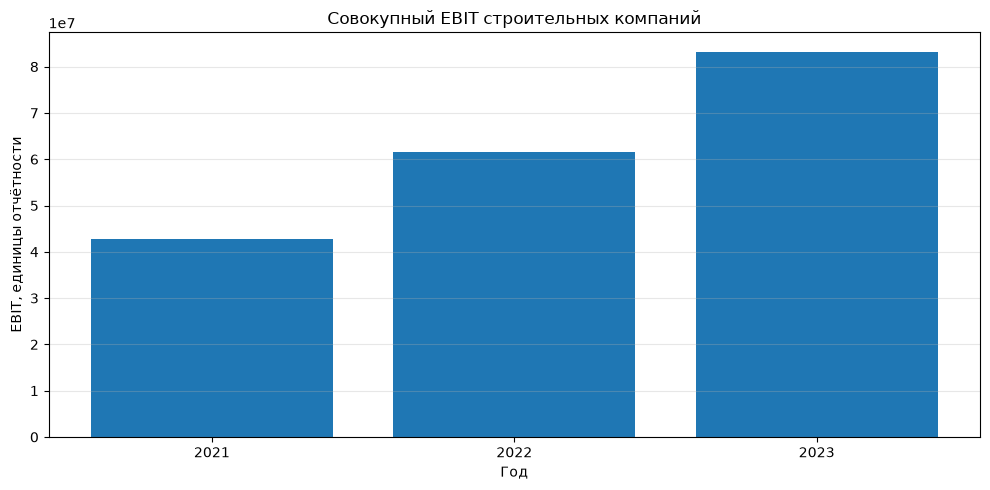

In [30]:

plt.figure(figsize=(10, 5))

plt.bar(
    summary.index.astype(str),
    summary["total_EBIT"]
)

plt.title("Совокупный EBIT строительных компаний")
plt.xlabel("Год")
plt.ylabel("EBIT, единицы отчётности")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("figures/ebit.png", dpi=200)
plt.show()


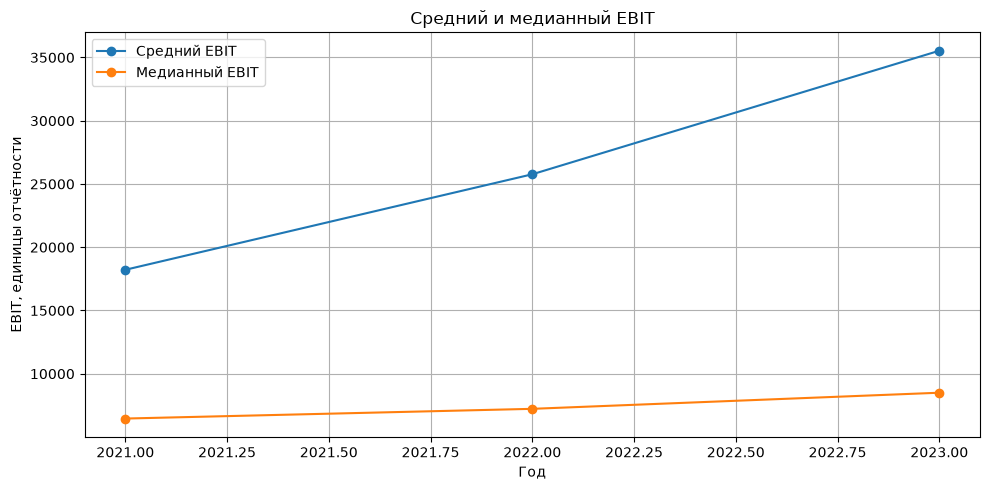

In [31]:

plt.figure(figsize=(10, 5))

plt.plot(
    summary.index,
    summary["mean_EBIT"],
    marker="o",
    label="Средний EBIT"
)

plt.plot(
    summary.index,
    summary["median_EBIT"],
    marker="o",
    label="Медианный EBIT"
)

plt.title("Средний и медианный EBIT")
plt.xlabel("Год")
plt.ylabel("EBIT, единицы отчётности")

plt.legend()
plt.grid()
plt.tight_layout()

plt.savefig("figures/mean_median.png", dpi=200)
plt.show()


In [32]:

profits = finance.pivot(
    index="ИНН",
    columns="year",
    values="net_profit"
)

growth = profits[[2021, 2023]].dropna()

growth = growth[growth[2021] > 0].copy()

growth["growth_pct"] = (
    (growth[2023] - growth[2021])
    / growth[2021] * 100
).round().astype(int)

display(growth.head())


year,2021,2023,growth_pct
ИНН,,,
0101009232,2061.0,20041.0,872
0104016125,1630.0,29171.0,1690
0105008695,3919.0,3710.0,-5
0105008744,238.0,1.0,-100
0105027747,47319.0,19534.0,-59


In [33]:

counts = (
    growth["growth_pct"]
    .value_counts()
    .sort_index()
)

display(counts.head(20))


growth_pct
-6432467    1
-2921231    1
-2463910    1
-863878     1
-854125     1
-661500     1
-538950     1
-475066     1
-317020     1
-285270     1
-243911     1
-200843     1
-182791     1
-151132     1
-131707     1
-103684     1
-93123      1
-62151      1
-61017      1
-45662      1
Name: count, dtype: int64

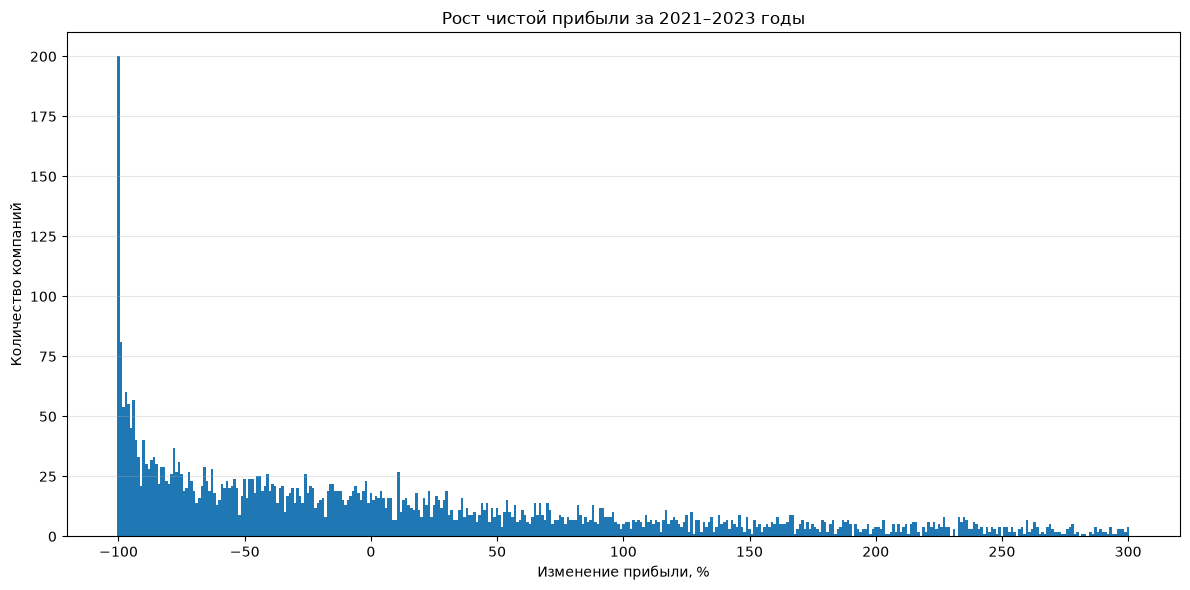

Компаний в расчёте: 6562
Компаний на графике: 4404


In [34]:

visible = counts[
    (counts.index >= -100)
    & (counts.index <= 300)
]

plt.figure(figsize=(12, 6))

plt.bar(
    visible.index,
    visible.values,
    width=1
)

plt.title("Рост чистой прибыли за 2021–2023 годы")
plt.xlabel("Изменение прибыли, %")
plt.ylabel("Количество компаний")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("figures/profit_growth.png", dpi=200)
plt.show()

print("Компаний в расчёте:", len(growth))
print("Компаний на графике:", visible.sum())


In [35]:

positive = (growth["growth_pct"] > 0).sum()
total = len(growth)

share = positive / total * 100 if total else float("nan")

print("Всего компаний:", total)
print("Компаний с ростом прибыли:", positive)
print(f"Доля с ростом: {share:.2f}%")


Всего компаний: 6562
Компаний с ростом прибыли: 3106
Доля с ростом: 47.33%


In [36]:

top500 = (
    finance[finance["year"] == 2023]
    .dropna(subset=["revenue"])
    .nlargest(500, "revenue")
    .copy()
)

top500 = top500.merge(
    companies[[
        "ИНН",
        "Наименование / ФИО",
        "Регион",
        "Город"
    ]].drop_duplicates("ИНН"),
    on="ИНН",
    how="left"
)

display(top500.head())


,ИНН,year,revenue,profit_before_tax,interest,net_profit,org_id,correction_id,correction_date,EBIT,Наименование / ФИО,Регион,Город
0,7708409097,2023,12516249.0,29537.0,NaN,23593.0,11943933,48222702,2024-03-20,NaN,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""СК-Г...",77 - г.Москва,NaN
1,7708309350,2023,11931988.0,1577.0,0.0,1262.0,10082903,49206127,2024-04-03,1577.0,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""СТРО...",20 - Чеченская Республика,NaN
2,9717029923,2023,7960613.0,4322.0,10669.0,1554.0,9791942,49022957,2024-04-01,14991.0,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""ОБЪЕ...",77 - г.Москва,NaN
3,7730032150,2023,6079785.0,46818.0,452082.0,35515.0,7144909,49669906,2024-04-05,498900.0,ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ПРОИЗ...,77 - г.Москва,NaN
4,7325124442,2023,5443642.0,672407.0,2540.0,535488.0,8149535,48349580,2024-03-23,674947.0,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""СПЕЦ...",34 - Волгоградская область,г Волгоград


In [37]:

def make_address(row):
    city = row["Город"]
    region = row["Регион"]

    city = "" if pd.isna(city) else str(city)

    region = "" if pd.isna(region) else str(region)
    region = re.sub(r"^\d+\s*-\s*", "", region)

    return ", ".join(
        x for x in [city, region, "Россия"] if x
    )

top500["address"] = top500.apply(
    make_address, axis=1
)

display(top500[["ИНН", "address"]].head())


,ИНН,address
0,7708409097,"г.Москва, Россия"
1,7708309350,"Чеченская Республика, Россия"
2,9717029923,"г.Москва, Россия"
3,7730032150,"г.Москва, Россия"
4,7325124442,"г Волгоград, Волгоградская область, Россия"


In [38]:

from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
from geopy.exc import GeopyError

geolocator = Nominatim(
    user_agent="construction_analysis_4120_course_project"
)

geocode = RateLimiter(
    geolocator.geocode,
    min_delay_seconds=1.1,
    max_retries=0
)

cache_path = Path("data/geocoding.json")

if cache_path.exists():
    geo_cache = json.loads(
        cache_path.read_text(encoding="utf-8")
    )
else:
    geo_cache = {}

for address in top500["address"].unique():
    if address in geo_cache:
        continue

    try:
        location = geocode(address, language="ru")
    except GeopyError as e:
        print("Геокодирование остановлено:", e)
        break

    geo_cache[address] = (
        [location.latitude, location.longitude]
        if location else [None, None]
    )

    cache_path.write_text(
        json.dumps(geo_cache, ensure_ascii=False),
        encoding="utf-8"
    )

top500["lat"] = top500["address"].map(
    lambda a: geo_cache.get(a, [None, None])[0]
)

top500["lon"] = top500["address"].map(
    lambda a: geo_cache.get(a, [None, None])[1]
)

print("Найдено координат:", top500["lat"].notna().sum())


Найдено координат: 490


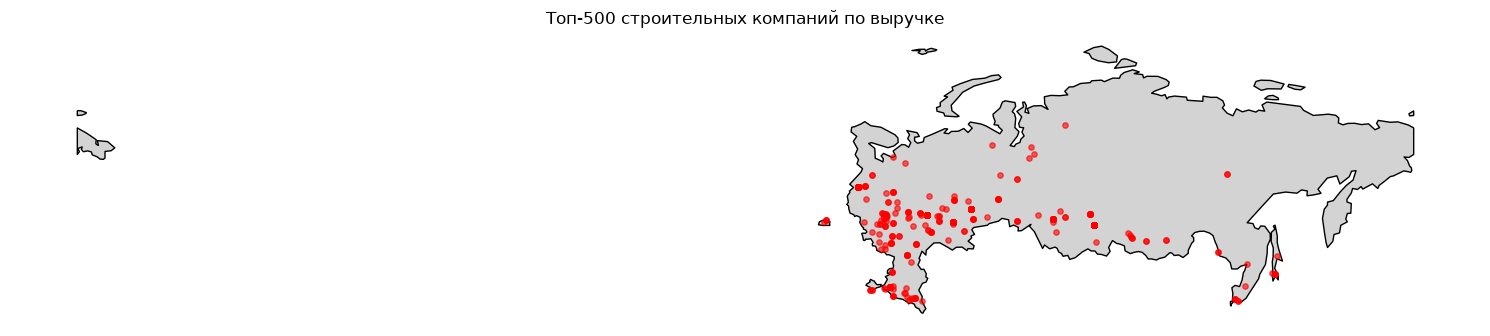

In [39]:

import geopandas as gpd
import zipfile

map_zip = "data/ne_110m_admin_0_countries.zip"

with zipfile.ZipFile(map_zip) as archive:
    archive.extractall("data/naturalearth")

world = gpd.read_file(
    "data/naturalearth/ne_110m_admin_0_countries.shp"
)

russia = world[world["ADMIN"] == "Russia"]

points = top500.dropna(
    subset=["lat", "lon"]
).copy()

geo = gpd.GeoDataFrame(
    points,
    geometry=gpd.points_from_xy(
        points["lon"], points["lat"]
    ),
    crs="EPSG:4326"
)

fig, ax = plt.subplots(figsize=(15, 8))

russia.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black"
)

geo.plot(
    ax=ax,
    color="red",
    markersize=15,
    alpha=0.6
)

plt.title("Топ-500 строительных компаний по выручке")
plt.axis("off")
plt.tight_layout()

plt.savefig("figures/top500_map.png", dpi=200)
plt.show()


# Выводы по анализу строительной отрасли России

1. Динамика финансовых показателей

За период 2021–2023 годов строительная отрасль продемонстрировала значительный рост финансовых показателей. Совокупный EBIT исследуемых компаний увеличился с 42,83 млн до 83,25 млн единиц отчётности, то есть примерно на 94,4%. Средний EBIT вырос с 18 217 до 35 533, а медианный — с 6 458 до 8 500 (на 31,6%).

Таким образом, финансовые результаты отрасли улучшились, однако рост среднего показателя значительно опережает рост медианного.

2. Изменение чистой прибыли компаний

Анализ изменения чистой прибыли за 2021–2023 годы охватил 6 562 компании с положительной прибылью в базовом году. Из них 3 106 предприятий продемонстрировали положительную динамику, что составляет 47,33% от общего количества.

Следовательно, у большинства исследованных компаний (52,67%) рост чистой прибыли отсутствовал. Это свидетельствует о неравномерном развитии отрасли: увеличение совокупных финансовых результатов не сопровождается ростом прибыли у большинства предприятий.

3. Неравномерность распределения прибыли

График среднего и медианного EBIT показывает значительный разрыв между показателями. В 2023 году средний EBIT составил 35 533, тогда как медианный — только 8 500.

Это свидетельствует о том, что сравнительно небольшая группа наиболее прибыльных предприятий оказывает существенное влияние на средние показатели отрасли. При этом финансовое положение типичной строительной компании улучшается значительно медленнее.

4. Географическое распределение компаний

Карта топ-500 строительных компаний по выручке показывает, что наибольшая концентрация крупных предприятий наблюдается в европейской части России. В восточных регионах количество представленных компаний значительно меньше.

Подобное распределение указывает на географическую неравномерность размещения крупнейших строительных организаций. При этом карта отражает места регистрации предприятий, которые могут не совпадать с расположением строительных объектов.

# Общий вывод

На основании проведённого анализа можно заключить, что строительная отрасль России обладает потенциалом дальнейшего развития, однако её финансовые результаты распределяются неравномерно.

С одной стороны, совокупный EBIT за 2021–2023 годы увеличился на 94,4%, что свидетельствует об улучшении финансовых результатов исследуемых предприятий.

С другой стороны, только 47,33% компаний продемонстрировали рост чистой прибыли. Значительный разрыв между средним и медианным EBIT также указывает на неравномерное распределение финансовых результатов.

Таким образом, отрасль можно оценить как умеренно перспективную, но с существенными различиями в финансовом положении отдельных компаний и регионов.

При оценке результатов необходимо учитывать, что исследование охватывает малые и средние юридические лица с ОКВЭД 41.20, имеющие доступную финансовую отчётность, а не весь строительный рынок России.